# Possession and pass-event detection

**Analytical question:** Recover candidate on-ball events.

**Stages in this notebook:** Player–ball vectors; proximity; stable possession; release/transit/reception; timing evaluation.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## Nearest-player possession candidates
Compute Euclidean player–ball distance for each frame. A two-metre radius is a chosen teaching threshold. Ball height filters flyovers, but duels and missing observations still require uncertainty. Supplied possession is useful for comparison, not a model input here.

,period,start,end,player,team,frames,duration_s
segment,,,,,,,
16,1,56,58,51050,1802,3,0.3
58,1,100,104,797298,1802,5,0.5
59,1,105,109,966114,871,5,0.5
73,1,123,127,560989,871,5,0.5
75,1,129,132,560882,1802,4,0.4
110,1,170,187,965697,1802,18,1.8
122,1,199,212,51050,1802,14,1.4
135,1,225,242,560983,1802,18,1.8
143,1,250,261,560986,1802,12,1.2


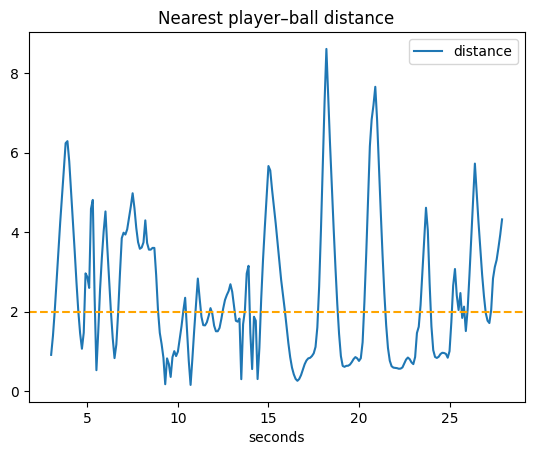

In [4]:
joined=observed.merge(wide[['period_id','frame_id','ball_x','ball_y','ball_z']],on=['period_id','frame_id'],validate='many_to_one')
joined['distance']=np.hypot(joined.x-joined.ball_x,joined.y-joined.ball_y)
valid=joined.dropna(subset=['distance'])
nearest=valid.loc[valid.groupby(['period_id','frame_id']).distance.idxmin()].sort_values(['period_id','frame_id']).copy()
nearest['candidate']=nearest.player_id.where(nearest.distance.le(2)&nearest.ball_z.fillna(0).le(2))
nearest['break']=nearest.period_id.ne(nearest.period_id.shift())|nearest.frame_id.diff().ne(1)|nearest.candidate.ne(nearest.candidate.shift())
nearest['segment']=nearest['break'].cumsum()
segments=nearest.groupby('segment').agg(period=('period_id','first'),start=('frame_id','min'),end=('frame_id','max'),player=('candidate','first'),team=('team_id','first'),frames=('frame_id','size'))
segments['duration_s']=segments.frames/10
stable=segments[segments.player.notna()&segments.duration_s.ge(.3)].copy()
display(stable.head(12))
nearest.head(250).plot(x='seconds',y='distance',title='Nearest player–ball distance')
plt.axhline(2,color='orange',ls='--')
plt.show()

### Intermediate steps: Inspect the distance calculation and nearest-player selection

Watch the threshold convert a continuous distance into a candidate label. A nearby player can still be an opponent in a duel.

Run the helper functions, inspect their returned arrays/tables, then compare the panels in calculation order.

#### Helper: `player_ball_vectors`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [5]:
def player_ball_vectors(players,ball_xy):
    return players[['x','y']].to_numpy()-np.asarray(ball_xy)

#### Helper: `vector_lengths`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [6]:
def vector_lengths(vectors):
    return np.sqrt((vectors**2).sum(axis=1))

,player_id,dx,dy,distance_m
36918,51002,-0.90,0.13,0.909340
55377,560984,-2.57,-8.47,8.851316
98448,287934,6.45,6.30,9.016235
43071,560882,-0.67,9.21,9.234338
30765,560986,-0.39,-9.28,9.288191
24612,795530,-10.48,0.42,10.488413
123060,560983,7.74,-7.12,10.516749
6153,966112,-0.76,11.00,11.026223


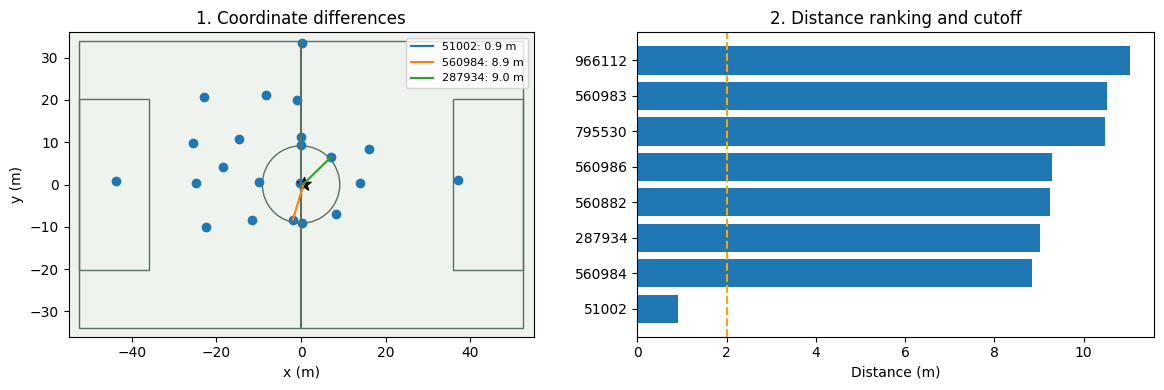

In [7]:
sample=nearest.iloc[0]
players=observed[observed.period_id.eq(sample.period_id)&observed.frame_id.eq(sample.frame_id)].copy()
ball_xy=np.array([sample.ball_x,sample.ball_y])
vectors=player_ball_vectors(players,ball_xy)
players['distance_m']=vector_lengths(vectors)
players['dx']=vectors[:,0]
players['dy']=vectors[:,1]
display(players[['player_id','dx','dy','distance_m']].sort_values('distance_m').head(8))
fig,axs=plt.subplots(1,2,figsize=(12,4))
pitch(axs[0])
axs[0].scatter(players.x,players.y)
axs[0].scatter(*ball_xy,c='black',marker='*',s=100)
for r in players.nsmallest(3,'distance_m').itertuples():axs[0].plot([r.x,ball_xy[0]],[r.y,ball_xy[1]],label=f'{r.player_id}: {r.distance_m:.1f} m')
axs[0].legend(fontsize=8)
axs[0].set_title('1. Coordinate differences')
rank=players.nsmallest(8,'distance_m')
axs[1].barh(rank.player_id,rank.distance_m)
axs[1].axvline(2,color='orange',ls='--')
axs[1].set(title='2. Distance ranking and cutoff',xlabel='Distance (m)')
plt.tight_layout()
plt.show()

## Release, transit and reception
Pair successive stable possession segments. A same-team identity change with finite ball displacement is a pass candidate. Limit the gap and reject missing ball trajectories. Interceptions, dribbles near teammates, deflections and aerial passes can still fool this baseline. Never equate these rows with verified pass events.

,period,release,reception,passer,receiver,travel_s,displacement_m
0,1,109,123,966114,560989,1.4,10.225380
1,1,132,170,560882,965697,3.8,27.147361
2,1,187,199,965697,51050,1.2,17.012010
3,1,212,225,51050,560983,1.3,16.841954
4,1,242,250,560983,560986,0.8,8.693590
5,1,343,358,11897,966114,1.5,14.703496
6,1,368,376,966114,795530,0.8,5.110773
7,1,385,398,795530,560984,1.3,16.305760
8,1,569,574,287934,51050,0.5,4.323806
9,1,1262,1281,51002,560986,1.9,7.681881


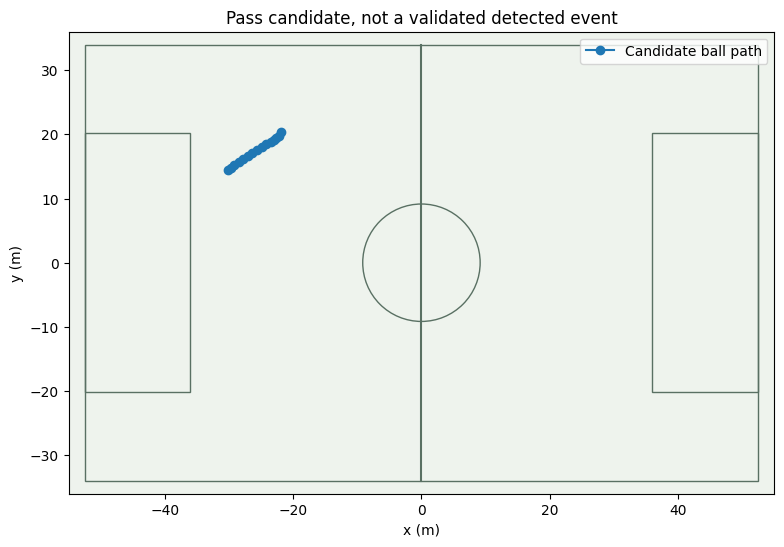

In [8]:
candidates=[]
for a,b in zip(stable.itertuples(),list(stable.itertuples())[1:]):
    if a.period!=b.period or a.player==b.player or a.team!=b.team:continue
    gap=b.start-a.end
    path=wide[wide.period_id.eq(a.period)&wide.frame_id.between(a.end,b.start)].sort_values('frame_id')
    if not 1<=gap<=40 or len(path)!=gap+1 or path[['ball_x','ball_y']].isna().any().any():continue
    displacement=np.linalg.norm(path[['ball_x','ball_y']].iloc[-1]-path[['ball_x','ball_y']].iloc[0])
    if displacement<3:continue
    candidates.append(dict(period=a.period,release=a.end,reception=b.start,passer=a.player,receiver=b.player,travel_s=gap/10,displacement_m=displacement))
passes=pd.DataFrame(candidates,columns=['period','release','reception','passer','receiver','travel_s','displacement_m'])
display(passes.head(10))
fig,ax=plt.subplots(figsize=(10,6))
pitch(ax)
if len(passes):
    p=passes.iloc[0];path=wide[wide.period_id.eq(p.period)&wide.frame_id.between(p.release,p.reception)]
    ax.plot(path.ball_x,path.ball_y,'o-',label='Candidate ball path');ax.legend()
ax.set_title('Pass candidate, not a validated detected event')
plt.show()

### Intermediate steps: Inspect ball steps before calling the sequence a pass

This diagnostic exposes irregular or missing ball samples. Release and reception candidates still require context and labels.

Run the helper functions, inspect their returned arrays/tables, then compare the panels in calculation order.

#### Helper: `ball_path_steps`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [9]:
def ball_path_steps(path):
    path=path.sort_values('frame_id').copy()
    path['dt']=path.timestamp.dt.total_seconds().diff()
    path['step_m']=np.hypot(path.ball_x.diff(),path.ball_y.diff())
    valid=path.frame_id.diff().eq(1)&path.dt.gt(0)
    path['ball_speed_mps']=(path.step_m/path.dt).where(valid)
    return path

,frame_id,ball_x,ball_y,dt,step_m,ball_speed_mps
69,109,-21.87,20.38,NaN,NaN,NaN
70,110,-22.26,19.82,0.1,0.682422,6.824222
71,111,-22.63,19.40,0.1,0.559732,5.597321
72,112,-23.04,19.08,0.1,0.520096,5.200961
73,113,-23.52,18.81,0.1,0.550727,5.507268
74,114,-24.15,18.49,0.1,0.706612,7.066116
75,115,-24.88,18.10,0.1,0.827647,8.276473
76,116,-25.64,17.63,0.1,0.893588,8.935883
77,117,-26.38,17.13,0.1,0.893085,8.930845
78,118,-27.09,16.65,0.1,0.857030,8.570298


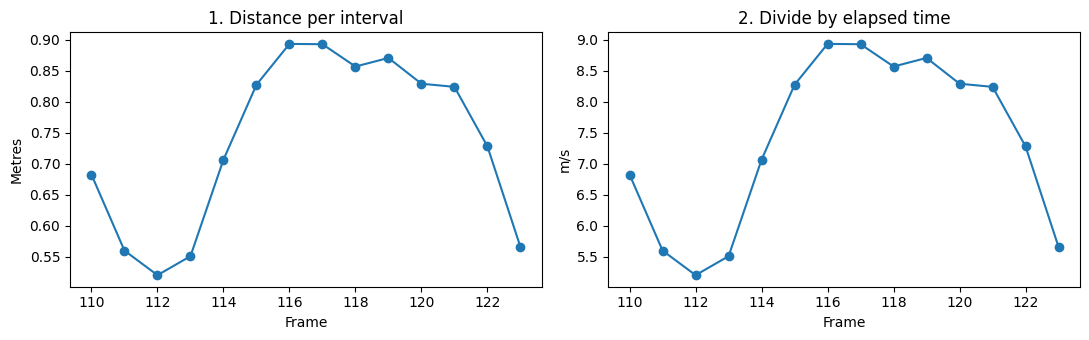

In [10]:
if len(passes):
    p=passes.iloc[0];path=ball_path_steps(wide[wide.period_id.eq(p.period)&wide.frame_id.between(p.release,p.reception)])
else:path=ball_path_steps(wide.head(30))
display(path[['frame_id','ball_x','ball_y','dt','step_m','ball_speed_mps']].head(10))
fig,axs=plt.subplots(1,2,figsize=(11,3.5))
axs[0].plot(path.frame_id,path.step_m,'o-')
axs[0].set(title='1. Distance per interval',ylabel='Metres',xlabel='Frame')
axs[1].plot(path.frame_id,path.ball_speed_mps,'o-')
axs[1].set(title='2. Divide by elapsed time',ylabel='m/s',xlabel='Frame')
plt.tight_layout()
plt.show()

## Timing-aware evaluation
For labeled events, a correct type and passer/receiver should also match within an explicit timing tolerance. Use one-to-one matching so multiple candidates cannot all claim the same true event. Tune thresholds only on training/validation matches. The function below measures timing matches, and can be applied within each event type and player pairing.

In [11]:
from scipy.optimize import linear_sum_assignment

#### Helper: `timing_scores`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [12]:
def timing_scores(predicted,truth,tolerance_s=.5):
    predicted=np.asarray(predicted);truth=np.asarray(truth)
    if not len(predicted) or not len(truth):return {'tp':0,'fp':len(predicted),'fn':len(truth)}
    delta=np.abs(predicted[:,None]-truth[None,:])
    # A large penalty first maximizes the count of eligible one-to-one matches.
    cost=np.where(delta<=tolerance_s,delta,1e6)
    rows,cols=linear_sum_assignment(cost);tp=int((delta[rows,cols]<=tolerance_s).sum())
    return {'tp':tp,'fp':len(predicted)-tp,'fn':len(truth)-tp}

In [13]:
assert timing_scores([1,1.1],[1],.2)=={'tp':1,'fp':1,'fn':0}
print('Synthetic unit check only:',timing_scores([1,3],[1.1,5],.2))

Synthetic unit check only: {'tp': 1, 'fp': 1, 'fn': 1}


**Tradeoff:** interpretable and inexpensive, but robust event recovery needs ball dynamics, aerial handling and video-reviewed labels. See [PathCRF](https://github.com/hyunsungkim-ds/pathcrf) for a richer research direction; this notebook does not reproduce it.

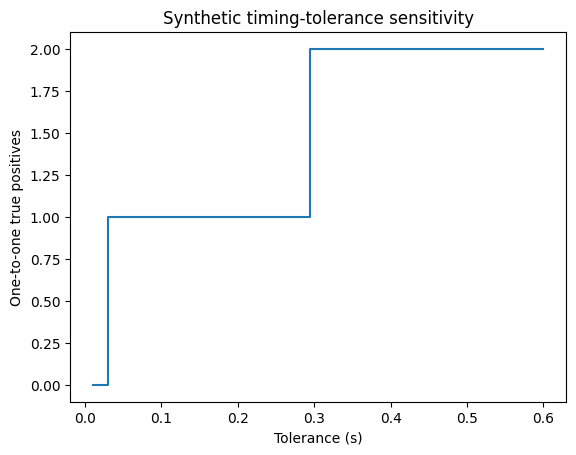

In [14]:
tolerances=np.linspace(.01,.6,30)
predicted=[1.,1.1,3.3]
truth=[1.05,3.,5.]
counts=[timing_scores(predicted,truth,t)['tp'] for t in tolerances]
plt.step(tolerances,counts)
plt.xlabel('Tolerance (s)')
plt.ylabel('One-to-one true positives')
plt.title('Synthetic timing-tolerance sensitivity')
plt.show()

## Review the full method
Trace each final quantity back through its helper functions, intermediate arrays and visual diagnostics. Change one modeling assumption and rerun its dependent cells. Review coverage, attack direction, phase context and evaluation design before interpreting real sample results. Keep synthetic demonstrations and proxy quantities separate from trained or production model outputs.

This notebook is deliberately self-contained. Shared *concepts* such as smoothing or graph normalization are repeated inline where needed; another notebook never needs to run first.
